# M5 Demand Forecasting

## 1. Project Objective

The objective of this project is to build a machine learning-based demand forecasting system using the M5 Walmart sales dataset.

The model forecasts daily unit demand for multiple product-store combinations using historical sales patterns, calendar information, and product/store identity.

### Project Scope

- **Dataset:** M5 Walmart Forecasting dataset
- **Products:** 100 HOBBIES items
- **Stores:** 10 stores across California, Texas, and Wisconsin
- **Forecasting series:** 1,000 product-store combinations
- **Forecast horizon:** 28 days
- **Forecasting approach:** Global machine learning model
- **Final model:** HistGradientBoostingRegressor
- **Evaluation metrics:** MAE and RMSE

The project also includes exploratory data analysis, baseline forecasting methods, feature engineering, hyperparameter experimentation, multi-window validation, error analysis, model explainability, and recursive multi-day forecasting.

# Phase 1 — Data Loading & Understanding

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

In [2]:
calendar = pd.read_csv("C:/Users/User/Desktop/Demand Forecasting/data/calendar.csv")
sales = pd.read_csv("C:/Users/User/Desktop/Demand Forecasting/data/sales_train_validation.csv")
prices = pd.read_csv("C:/Users/User/Desktop/Demand Forecasting/data/sell_prices.csv")

In [3]:
print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)


In [4]:
sales["store_id"].unique()

array(['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1',
       'WI_2', 'WI_3'], dtype=object)

In [5]:
selected_stores = sales["store_id"].unique()

len(selected_stores)

10

In [6]:
selected_items = sales["item_id"].unique()[:100]

len(selected_items)

100

# Phase 2 — Data Cleaning & Preparation

In [7]:
sales_subset = sales[
    sales["store_id"].isin(selected_stores) &
    sales["item_id"].isin(selected_items)
].copy()

In [8]:
print("Subset shape:", sales_subset.shape)
print("Stores:", sales_subset["store_id"].nunique())
print("Items:", sales_subset["item_id"].nunique())

Subset shape: (1000, 1919)
Stores: 10
Items: 100


In [9]:
sales_subset[
    ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
].head()

,id,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA


In [10]:
sales_subset.groupby("store_id")["item_id"].nunique()

store_id
CA_1    100
CA_2    100
CA_3    100
CA_4    100
TX_1    100
TX_2    100
TX_3    100
WI_1    100
WI_2    100
WI_3    100
Name: item_id, dtype: int64

In [11]:
sales_subset["id"].nunique()

1000

In [12]:
sales_subset.shape

(1000, 1919)

In [13]:
day_cols = [
    col for col in sales_subset.columns
    if col.startswith("d_")
]

sales_long = sales_subset.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_cols,
    var_name="d",
    value_name="sales"
)

In [14]:
sales_long.shape

(1913000, 8)

In [15]:
sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [16]:
sales_long = sales_long.merge(
    calendar,
    on="d",
    how="left"
)

In [17]:
sales_long.shape

(1913000, 21)

In [18]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [19]:
prices.duplicated(
    subset=["store_id", "item_id", "wm_yr_wk"]
).sum()

np.int64(0)

In [20]:
sales_long = sales_long.merge(
    prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

# Phase 3 — Exploratory Data Analysis

In [21]:
sales_long.shape

(1913000, 22)

In [22]:
sales_long["sell_price"].isna().sum()

np.int64(319550)

In [23]:
sales_long.loc[
    sales_long["sell_price"].isna(),
    "sales"
].value_counts()

sales
0    319550
Name: count, dtype: int64

In [24]:
print("Rows:", len(sales_long))

print(
    "Duplicate observations:",
    sales_long.duplicated(
        subset=["id", "d"]
    ).sum()
)

Rows: 1913000
Duplicate observations: 0


In [25]:
sales_long[
    [
        "id",
        "item_id",
        "store_id",
        "d",
        "date",
        "wm_yr_wk",
        "sales",
        "sell_price"
    ]
].head(10)

,id,item_id,store_id,d,date,wm_yr_wk,sales,sell_price
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,CA_1,d_1,2011-01-29,11101,0,NaN
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,CA_1,d_1,2011-01-29,11101,0,NaN
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,CA_1,d_1,2011-01-29,11101,0,NaN
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,CA_1,d_1,2011-01-29,11101,0,NaN
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,CA_1,d_1,2011-01-29,11101,0,NaN
5,HOBBIES_1_006_CA_1_validation,HOBBIES_1_006,CA_1,d_1,2011-01-29,11101,0,NaN
6,HOBBIES_1_007_CA_1_validation,HOBBIES_1_007,CA_1,d_1,2011-01-29,11101,0,NaN
7,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,CA_1,d_1,2011-01-29,11101,12,0.46
8,HOBBIES_1_009_CA_1_validation,HOBBIES_1_009,CA_1,d_1,2011-01-29,11101,2,1.56
9,HOBBIES_1_010_CA_1_validation,HOBBIES_1_010,CA_1,d_1,2011-01-29,11101,0,3.17


In [26]:
sales_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1913000 entries, 0 to 1912999
Data columns (total 22 columns):
 #   Column        Dtype  
---  ------        -----  
 0   id            object 
 1   item_id       object 
 2   dept_id       object 
 3   cat_id        object 
 4   store_id      object 
 5   state_id      object 
 6   d             object 
 7   sales         int64  
 8   date          object 
 9   wm_yr_wk      int64  
 10  weekday       object 
 11  wday          int64  
 12  month         int64  
 13  year          int64  
 14  event_name_1  object 
 15  event_type_1  object 
 16  event_name_2  object 
 17  event_type_2  object 
 18  snap_CA       int64  
 19  snap_TX       int64  
 20  snap_WI       int64  
 21  sell_price    float64
dtypes: float64(1), int64(8), object(13)
memory usage: 321.1+ MB


In [27]:
sales_long["date"] = pd.to_datetime(sales_long["date"])

In [28]:
sales_long = sales_long.sort_values(
    ["id", "date"]
).reset_index(drop=True)

# Phase 4 — Forecasting Setup & Feature Engineering

In [29]:
max_date = sales_long["date"].max()

validation_start = max_date - pd.Timedelta(days=6)

print("Maximum date:", max_date)
print("Validation starts:", validation_start)

Maximum date: 2016-04-24 00:00:00
Validation starts: 2016-04-18 00:00:00


In [30]:
train = sales_long[
    sales_long["date"] < validation_start
].copy()

validation = sales_long[
    sales_long["date"] >= validation_start
].copy()

In [31]:
print("Training shape:", train.shape)
print("Validation shape:", validation.shape)

print(
    "Training dates:",
    train["date"].min(),
    "to",
    train["date"].max()
)

print(
    "Validation dates:",
    validation["date"].min(),
    "to",
    validation["date"].max()
)

Training shape: (1906000, 22)
Validation shape: (7000, 22)
Training dates: 2011-01-29 00:00:00 to 2016-04-17 00:00:00
Validation dates: 2016-04-18 00:00:00 to 2016-04-24 00:00:00


In [32]:
validation.groupby("id")["date"].nunique().value_counts()

date
7    1000
Name: count, dtype: int64

In [33]:
train["date"].max() < validation["date"].min()

True

In [34]:
lag_periods = [1, 7, 14, 28]

for lag in lag_periods:
    sales_long[f"lag_{lag}"] = (
        sales_long.groupby("id")["sales"].shift(lag)
    )

In [35]:
sales_long[
    sales_long["id"] == sales_long["id"].iloc[0]
][
    ["id", "date", "sales", "lag_1", "lag_7", "lag_14", "lag_28"]
].head(35)

,id,date,sales,lag_1,lag_7,lag_14,lag_28
0,HOBBIES_1_001_CA_1_validation,2011-01-29,0,NaN,NaN,NaN,NaN
1,HOBBIES_1_001_CA_1_validation,2011-01-30,0,0.0,NaN,NaN,NaN
2,HOBBIES_1_001_CA_1_validation,2011-01-31,0,0.0,NaN,NaN,NaN
3,HOBBIES_1_001_CA_1_validation,2011-02-01,0,0.0,NaN,NaN,NaN
4,HOBBIES_1_001_CA_1_validation,2011-02-02,0,0.0,NaN,NaN,NaN
5,HOBBIES_1_001_CA_1_validation,2011-02-03,0,0.0,NaN,NaN,NaN
6,HOBBIES_1_001_CA_1_validation,2011-02-04,0,0.0,NaN,NaN,NaN
7,HOBBIES_1_001_CA_1_validation,2011-02-05,0,0.0,0.0,NaN,NaN
8,HOBBIES_1_001_CA_1_validation,2011-02-06,0,0.0,0.0,NaN,NaN
9,HOBBIES_1_001_CA_1_validation,2011-02-07,0,0.0,0.0,NaN,NaN


In [36]:
grouped_sales = sales_long.groupby("id")["sales"]

sales_long["rolling_mean_7"] = (
    grouped_sales.shift(1)
    .rolling(7)
    .mean()
)

sales_long["rolling_mean_14"] = (
    grouped_sales.shift(1)
    .rolling(14)
    .mean()
)

sales_long["rolling_mean_28"] = (
    grouped_sales.shift(1)
    .rolling(28)
    .mean()
)

In [37]:
sales_long[
    [
        "date",
        "sales",
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_14",
        "rolling_mean_28"
    ]
].head(35)

,date,sales,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_14,rolling_mean_28
0,2011-01-29,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2011-01-30,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2011-01-31,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2011-02-01,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2011-02-02,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2011-02-03,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2011-02-04,0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2011-02-05,0,0.0,0.0,NaN,NaN,0.0,NaN,NaN
8,2011-02-06,0,0.0,0.0,NaN,NaN,0.0,NaN,NaN
9,2011-02-07,0,0.0,0.0,NaN,NaN,0.0,NaN,NaN


In [38]:
sales_long[
    [
        "lag_1",
        "lag_7",
        "lag_14",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_14",
        "rolling_mean_28"
    ]
].isna().sum()

lag_1               1000
lag_7               7000
lag_14             14000
lag_28             28000
rolling_mean_7      7000
rolling_mean_14    14000
rolling_mean_28    28000
dtype: int64

In [39]:
sales_long["day_of_week"] = sales_long["date"].dt.dayofweek
sales_long["month"] = sales_long["date"].dt.month
sales_long["year"] = sales_long["date"].dt.year
sales_long["day_of_month"] = sales_long["date"].dt.day
sales_long["is_weekend"] = (
    sales_long["day_of_week"] >= 5
).astype(int)

In [40]:
sales_long["is_event"] = (
    sales_long["event_name_1"].notna() |
    sales_long["event_name_2"].notna()
).astype(int)

In [41]:
sales_long[
    [
        "date",
        "day_of_week",
        "month",
        "year",
        "day_of_month",
        "is_weekend",
        "is_event",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
].head()

,date,day_of_week,month,year,day_of_month,is_weekend,is_event,snap_CA,snap_TX,snap_WI
0,2011-01-29,5,1,2011,29,1,0,0,0,0
1,2011-01-30,6,1,2011,30,1,0,0,0,0
2,2011-01-31,0,1,2011,31,0,0,0,0,0
3,2011-02-01,1,2,2011,1,0,0,1,1,0
4,2011-02-02,2,2,2011,2,0,0,1,0,1


In [42]:
sales_long[
    ["day_of_week", "month", "year", "day_of_month",
     "is_weekend", "is_event"]
].isna().sum()

day_of_week     0
month           0
year            0
day_of_month    0
is_weekend      0
is_event        0
dtype: int64

In [43]:
feature_columns = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "year",
    "day_of_month",
    "is_weekend",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

In [44]:
model_data = sales_long.dropna(
    subset=feature_columns
).copy()

In [45]:
print("Before:", sales_long.shape)
print("After:", model_data.shape)

Before: (1913000, 33)
After: (1885000, 33)


# Phase 5 — Baseline & Model Training

In [46]:
train_ml = model_data[
    model_data["date"] < validation_start
].copy()

validation_ml = model_data[
    model_data["date"] >= validation_start
].copy()

In [47]:
print("Training:", train_ml.shape)
print("Validation:", validation_ml.shape)

Training: (1878000, 33)
Validation: (7000, 33)


In [48]:
print(train_ml["date"].min(), "→", train_ml["date"].max())
print(validation_ml["date"].min(), "→", validation_ml["date"].max())

2011-02-26 00:00:00 → 2016-04-17 00:00:00
2016-04-18 00:00:00 → 2016-04-24 00:00:00


In [49]:
X_train = train_ml[feature_columns]
y_train = train_ml["sales"]

X_validation = validation_ml[feature_columns]
y_validation = validation_ml["sales"]

In [50]:
print(X_train.shape)
print(y_train.shape)
print(X_validation.shape)
print(y_validation.shape)

(1878000, 16)
(1878000,)
(7000, 16)
(7000,)


In [51]:
print("Training NaNs:", X_train.isna().sum().sum())
print("Validation NaNs:", X_validation.isna().sum().sum())

Training NaNs: 0
Validation NaNs: 0


In [52]:
from sklearn.ensemble import RandomForestRegressor

In [53]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

In [54]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [55]:
rf_predictions = rf_model.predict(X_validation)

In [56]:
rf_mae = mean_absolute_error(
    y_validation,
    rf_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        rf_predictions
    )
)

print("Random Forest MAE:", rf_mae)
print("Random Forest RMSE:", rf_rmse)

Random Forest MAE: 0.9514059251792151
Random Forest RMSE: 1.8640773505394392


In [57]:
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

print(feature_importance)

            feature  importance
6   rolling_mean_28    0.381845
5   rolling_mean_14    0.094432
4    rolling_mean_7    0.085527
10     day_of_month    0.072205
8             month    0.056086
2            lag_14    0.054904
3            lag_28    0.054257
1             lag_7    0.053738
0             lag_1    0.049817
9              year    0.039169
7       day_of_week    0.028211
14          snap_TX    0.008034
15          snap_WI    0.007886
12         is_event    0.007008
13          snap_CA    0.004242
11       is_weekend    0.002639


In [58]:
from sklearn.ensemble import HistGradientBoostingRegressor

print("HistGradientBoostingRegressor imported successfully")

HistGradientBoostingRegressor imported successfully


In [59]:
hgb_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(X_train, y_train)

hgb_predictions = hgb_model.predict(X_validation)

In [60]:
hgb_mae = mean_absolute_error(y_validation, hgb_predictions)
hgb_rmse = mean_squared_error(y_validation, hgb_predictions) ** 0.5

print("HGB MAE:", hgb_mae)
print("HGB RMSE:", hgb_rmse)

HGB MAE: 0.8859989579170355
HGB RMSE: 1.8096882702338573


In [61]:
sales_long["rolling_mean_7"] = (
    sales_long.groupby("id")["sales"]
    .transform(lambda s: s.shift(1).rolling(7).mean())
)

sales_long["rolling_mean_14"] = (
    sales_long.groupby("id")["sales"]
    .transform(lambda s: s.shift(1).rolling(14).mean())
)

sales_long["rolling_mean_28"] = (
    sales_long.groupby("id")["sales"]
    .transform(lambda s: s.shift(1).rolling(28).mean())
)

In [62]:
for lag in [1, 7, 14, 28]:
    sales_long[f"lag_{lag}"] = (
        sales_long.groupby("id")["sales"].shift(lag)
    )

In [63]:
model_data = sales_long.dropna(subset=feature_columns).copy()

train_ml = model_data[model_data["date"] < validation_start].copy()
validation_ml = model_data[model_data["date"] >= validation_start].copy()

X_train = train_ml[feature_columns]
y_train = train_ml["sales"]

X_validation = validation_ml[feature_columns]
y_validation = validation_ml["sales"]

In [64]:
hgb_mae = mean_absolute_error(y_validation, hgb_predictions)
hgb_rmse = mean_squared_error(y_validation, hgb_predictions) ** 0.5

print("HGB MAE:", hgb_mae)
print("HGB RMSE:", hgb_rmse)

HGB MAE: 0.8859989579170355
HGB RMSE: 1.8096882702338573


In [65]:
import inspect
print(inspect.signature(HistGradientBoostingRegressor))

(loss='squared_error', *, quantile=None, learning_rate=0.1, max_iter=100, max_leaf_nodes=31, max_depth=None, min_samples_leaf=20, l2_regularization=0.0, max_features=1.0, max_bins=255, categorical_features='from_dtype', monotonic_cst=None, interaction_cst=None, warm_start=False, early_stopping='auto', scoring='loss', validation_fraction=0.1, n_iter_no_change=10, tol=1e-07, verbose=0, random_state=None)


In [66]:
categorical_features='from_dtype'

In [67]:
model_data_cat = model_data.copy()

model_data_cat["item_id"] = model_data_cat["item_id"].astype("category")
model_data_cat["store_id"] = model_data_cat["store_id"].astype("category")

In [68]:
train_cat = model_data_cat[model_data_cat["date"] < validation_start]
validation_cat = model_data_cat[model_data_cat["date"] >= validation_start]

In [69]:
categorical_features = ["item_id", "store_id"]

feature_columns_cat = feature_columns + categorical_features

In [70]:
X_train_cat = train_cat[feature_columns_cat]
y_train_cat = train_cat["sales"]

X_validation_cat = validation_cat[feature_columns_cat]
y_validation_cat = validation_cat["sales"]

In [71]:
hgb_identity = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42
)

hgb_identity.fit(X_train_cat, y_train_cat)

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 

In [72]:
hgb_identity_predictions = hgb_identity.predict(X_validation_cat)

In [73]:
HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42
)

,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",100
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 

In [74]:
feature_columns_final = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "year",
    "day_of_month",
    "is_weekend",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

categorical_features = ["item_id", "store_id"]

feature_columns_final_cat = (
    feature_columns_final + categorical_features
)

In [75]:
baseline_params = {
    "max_iter": 100,
    "learning_rate": 0.1,
    "max_leaf_nodes": 31,
    "l2_regularization": 1.0
}

In [76]:
tuning_configs = [
    {
        "name": "Higher iterations",
        "max_iter": 200,
        "learning_rate": 0.1,
        "max_leaf_nodes": 31,
        "l2_regularization": 1.0
    },
    {
        "name": "Lower learning rate",
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 31,
        "l2_regularization": 1.0
    },
    {
        "name": "Smaller trees",
        "max_iter": 100,
        "learning_rate": 0.1,
        "max_leaf_nodes": 15,
        "l2_regularization": 1.0
    },
    {
        "name": "Larger trees",
        "max_iter": 100,
        "learning_rate": 0.1,
        "max_leaf_nodes": 63,
        "l2_regularization": 1.0
    },
    {
        "name": "Higher regularization",
        "max_iter": 100,
        "learning_rate": 0.1,
        "max_leaf_nodes": 31,
        "l2_regularization": 5.0
    },
    {
        "name": "Low LR + larger trees",
        "max_iter": 200,
        "learning_rate": 0.05,
        "max_leaf_nodes": 63,
        "l2_regularization": 1.0
    }
]

# Phase 6 — Model Evaluation & Validation

In [77]:
tuning_results = []

for config in tuning_configs:

    print(f"Training: {config['name']}")

    model = HistGradientBoostingRegressor(
        max_iter=config["max_iter"],
        learning_rate=config["learning_rate"],
        max_leaf_nodes=config["max_leaf_nodes"],
        l2_regularization=config["l2_regularization"],
        categorical_features="from_dtype",
        random_state=42
    )

    model.fit(X_train_cat, y_train_cat)

    predictions = model.predict(X_validation_cat)

    mae = mean_absolute_error(
        y_validation_cat,
        predictions
    )

    rmse = mean_squared_error(
        y_validation_cat,
        predictions
    ) ** 0.5

    tuning_results.append({
        "Model": config["name"],
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print("-" * 40)

Training: Higher iterations
MAE: 0.8758
RMSE: 1.7917
----------------------------------------
Training: Lower learning rate
MAE: 0.8772
RMSE: 1.7948
----------------------------------------
Training: Smaller trees
MAE: 0.8794
RMSE: 1.8050
----------------------------------------
Training: Larger trees
MAE: 0.8784
RMSE: 1.7980
----------------------------------------
Training: Higher regularization
MAE: 0.8786
RMSE: 1.7996
----------------------------------------
Training: Low LR + larger trees
MAE: 0.8776
RMSE: 1.7985
----------------------------------------


In [78]:
validation_windows = [
    max_date - pd.Timedelta(days=6),
    max_date - pd.Timedelta(days=34),
    max_date - pd.Timedelta(days=62),
    max_date - pd.Timedelta(days=90)
]

validation_windows

[Timestamp('2016-04-18 00:00:00'),
 Timestamp('2016-03-21 00:00:00'),
 Timestamp('2016-02-22 00:00:00'),
 Timestamp('2016-01-25 00:00:00')]

In [79]:
multi_window_results = []

for i, window_start in enumerate(validation_windows, start=1):

    print(f"Running validation window {i}...")
    
    train_window = model_data_cat[
        model_data_cat["date"] < window_start
    ]

    validation_end = window_start + pd.Timedelta(days=6)

    validation_window = model_data_cat[
        (model_data_cat["date"] >= window_start) &
        (model_data_cat["date"] <= validation_end)
    ]

    X_train_window = train_window[feature_columns_final_cat]
    y_train_window = train_window["sales"]

    X_validation_window = validation_window[feature_columns_final_cat]
    y_validation_window = validation_window["sales"]

    model = HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        categorical_features="from_dtype",
        random_state=42
    )

    model.fit(
        X_train_window,
        y_train_window
    )

    predictions = model.predict(
        X_validation_window
    )

    mae = mean_absolute_error(
        y_validation_window,
        predictions
    )

    rmse = mean_squared_error(
        y_validation_window,
        predictions
    ) ** 0.5

    multi_window_results.append({
        "Window": i,
        "Start": window_start,
        "End": validation_end,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"MAE: {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print("-" * 40)

Running validation window 1...
MAE: 0.8758
RMSE: 1.7917
----------------------------------------
Running validation window 2...
MAE: 0.8433
RMSE: 1.7696
----------------------------------------
Running validation window 3...
MAE: 0.8686
RMSE: 1.9642
----------------------------------------
Running validation window 4...
MAE: 0.8352
RMSE: 1.9194
----------------------------------------


In [80]:
multi_window_df = pd.DataFrame(multi_window_results)

multi_window_df

,Window,Start,End,MAE,RMSE
0,1,2016-04-18,2016-04-24,0.875791,1.791693
1,2,2016-03-21,2016-03-27,0.843321,1.769571
2,3,2016-02-22,2016-02-28,0.868600,1.964152
3,4,2016-01-25,2016-01-31,0.835157,1.919368


In [81]:
print(
    "Average MAE:",
    multi_window_df["MAE"].mean()
)

print(
    "Average RMSE:",
    multi_window_df["RMSE"].mean()
)

print(
    "MAE Std:",
    multi_window_df["MAE"].std()
)

print(
    "RMSE Std:",
    multi_window_df["RMSE"].std()
)

Average MAE: 0.8557170868359296
Average RMSE: 1.8611961795834842
MAE Std: 0.019539033752030362
RMSE Std: 0.09523610793645405


In [82]:
final_validation_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42
)

final_validation_model.fit(
    X_train_cat,
    y_train_cat
)

final_predictions = final_validation_model.predict(
    X_validation_cat
)

In [83]:
error_analysis = validation_cat[
    ["id", "item_id", "store_id", "date", "sales"]
].copy()

error_analysis["prediction"] = final_predictions

error_analysis["absolute_error"] = (
    error_analysis["sales"] -
    error_analysis["prediction"]
).abs()

error_analysis["error"] = (
    error_analysis["sales"] -
    error_analysis["prediction"]
)

In [84]:
print(
    error_analysis["absolute_error"].describe()
)

count    7000.000000
mean        0.875791
std         1.563171
min         0.000629
25%         0.224797
50%         0.441156
75%         0.852351
max        27.994557
Name: absolute_error, dtype: float64


In [85]:
worst_predictions = error_analysis.sort_values(
    "absolute_error",
    ascending=False
).head(20)

worst_predictions

,id,item_id,store_id,date,sales,prediction,absolute_error,error
135816,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,CA_1,2016-04-18,37,9.005443,27.994557,27.994557
353904,HOBBIES_1_019_TX_1_validation,HOBBIES_1_019,TX_1,2016-04-24,32,4.126141,27.873859,27.873859
813021,HOBBIES_1_043_TX_1_validation,HOBBIES_1_043,TX_1,2016-04-21,27,2.925337,24.074663,24.074663
1668129,HOBBIES_1_090_CA_2_validation,HOBBIES_1_090,CA_2,2016-04-18,26,2.095538,23.904462,23.904462
1480659,HOBBIES_1_080_CA_4_validation,HOBBIES_1_080,CA_4,2016-04-22,28,4.695653,23.304347,23.304347
1476832,HOBBIES_1_080_CA_2_validation,HOBBIES_1_080,CA_2,2016-04-21,25,2.165433,22.834567,22.834567
281210,HOBBIES_1_015_TX_3_validation,HOBBIES_1_015,TX_3,2016-04-24,27,5.012157,21.987843,21.987843
612158,HOBBIES_1_032_WI_3_validation,HOBBIES_1_032,WI_3,2016-04-23,24,3.142673,20.857327,20.857327
608328,HOBBIES_1_032_WI_1_validation,HOBBIES_1_032,WI_1,2016-04-19,24,4.353916,19.646084,19.646084
1249187,HOBBIES_1_067_CA_3_validation,HOBBIES_1_067,CA_3,2016-04-23,25,5.569194,19.430806,19.430806


In [86]:
store_errors = (
    error_analysis
    .groupby("store_id")
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2)))
    )
    .sort_values("MAE", ascending=False)
)

store_errors

,MAE,RMSE
store_id,,
CA_3,1.134320,2.108642
CA_1,1.081290,2.278483
CA_2,1.035569,2.222639
CA_4,0.880317,1.912798
TX_3,0.832235,1.620643
WI_1,0.831202,1.591776
TX_2,0.798011,1.279150
TX_1,0.793941,1.912329
WI_3,0.703878,1.460797


In [87]:
item_errors = (
    error_analysis
    .groupby("item_id")
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2))),
        actual_mean=("sales", "mean")
    )
    .sort_values("MAE", ascending=False)
)

item_errors.head(20)

,MAE,RMSE,actual_mean
item_id,,,
HOBBIES_1_048,4.348996,5.520779,7.057143
HOBBIES_1_019,3.558696,5.280356,3.942857
HOBBIES_1_103,3.532801,5.195586,3.471429
HOBBIES_1_067,3.240808,4.585315,2.957143
HOBBIES_1_008,3.210221,4.730265,3.957143
HOBBIES_1_015,3.115624,4.744539,3.714286
HOBBIES_1_032,3.042971,4.640564,3.257143
HOBBIES_1_080,2.444981,4.806784,2.300000
HOBBIES_1_030,2.269627,3.243880,2.557143


In [88]:
error_analysis["is_zero_actual"] = (
    error_analysis["sales"] == 0
)

print(
    error_analysis
    .groupby("is_zero_actual")["absolute_error"]
    .mean()
)

is_zero_actual
False    1.489912
True     0.539260
Name: absolute_error, dtype: float64


In [89]:
error_analysis["day_of_week"] = (
    error_analysis["date"].dt.day_name()
)

weekday_errors = (
    error_analysis
    .groupby("day_of_week")
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2))),
        mean_actual=("sales", "mean")
    )
)

weekday_errors

,MAE,RMSE,mean_actual
day_of_week,,,
Friday,0.913851,1.834222,0.933
Monday,0.826035,1.878599,0.787
Saturday,0.978680,1.906187,1.098
Sunday,0.965640,1.948201,1.110
Thursday,0.825360,1.791358,0.723
Tuesday,0.798228,1.625586,0.740
Wednesday,0.822740,1.515624,0.750


In [90]:
error_analysis["demand_level"] = pd.cut(
    error_analysis["sales"],
    bins=[-1, 0, 2, 5, 10, float("inf")],
    labels=["Zero", "Low", "Medium", "High", "Very High"]
)

demand_errors = (
    error_analysis
    .groupby("demand_level", observed=True)
    .agg(
        MAE=("absolute_error", "mean"),
        RMSE=("error", lambda x: np.sqrt(np.mean(x**2))),
        mean_actual=("sales", "mean"),
        count=("sales", "size")
    )
)

demand_errors

,MAE,RMSE,mean_actual,count
demand_level,,,,
Zero,0.539260,0.934432,0.000000,4522
Low,0.840851,1.104876,1.276781,1839
Medium,1.937647,2.320524,3.634033,429
High,3.668272,4.125451,7.195489,133
Very High,10.734370,12.328874,16.584416,77


# Phase 7 — Model Explainability

In [91]:
from sklearn.inspection import permutation_importance

In [92]:
perm_result = permutation_importance(
    final_validation_model,
    X_validation_cat,
    y_validation_cat,
    scoring="neg_mean_absolute_error",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

In [93]:
importance_df = pd.DataFrame({
    "feature": X_validation_cat.columns,
    "importance": perm_result.importances_mean
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

importance_df

,feature,importance
6,rolling_mean_28,0.213324
16,item_id,0.023319
5,rolling_mean_14,0.016177
7,day_of_week,0.013581
4,rolling_mean_7,0.004951
17,store_id,0.002016
0,lag_1,0.001392
11,is_weekend,0.000261
10,day_of_month,0.000107
13,snap_CA,0.000000


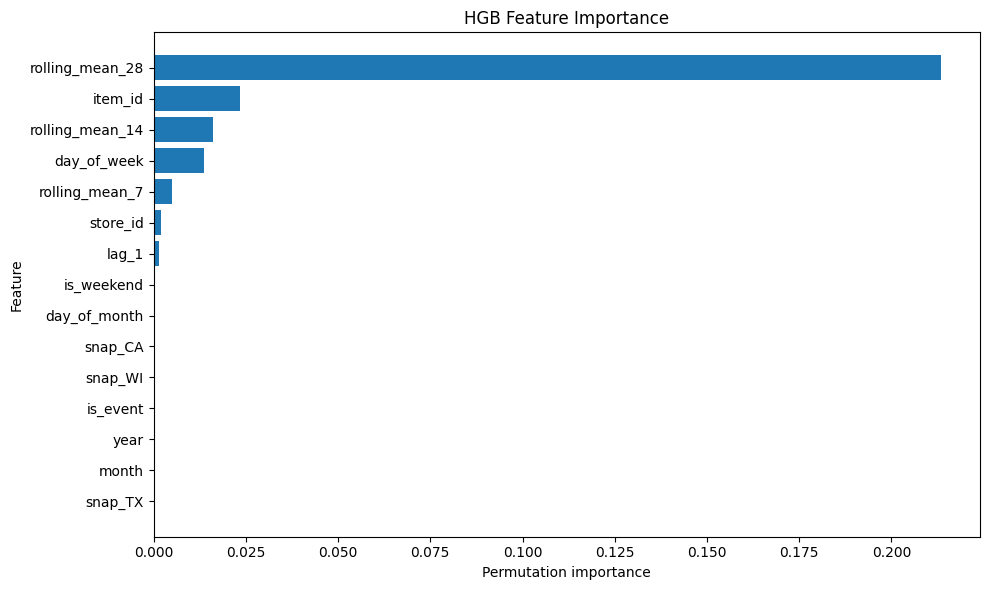

In [94]:
top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["feature"][::-1],
    top_features["importance"][::-1]
)

plt.xlabel("Permutation importance")
plt.ylabel("Feature")
plt.title("HGB Feature Importance")

plt.tight_layout()
plt.show()

In [95]:
seasonal_predictions = validation_cat["lag_7"]

seasonal_mae = mean_absolute_error(
    y_validation_cat,
    seasonal_predictions
)

seasonal_rmse = mean_squared_error(
    y_validation_cat,
    seasonal_predictions
) ** 0.5

print("Seasonal Naive MAE:", seasonal_mae)
print("Seasonal Naive RMSE:", seasonal_rmse)

Seasonal Naive MAE: 1.0527142857142857
Seasonal Naive RMSE: 2.5547434872633077


# Phase 8 — Final Model & 28-Day Forecast

In [96]:
final_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    random_state=42
)

X_full = model_data_cat[feature_columns_final_cat]
y_full = model_data_cat["sales"]

final_model.fit(X_full, y_full)


,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",200
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",1.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""category"" are considered to be categorical features. The input must be an object exposing a ``__dataframe__`` method such as pandas or polars DataFrames to use this feature.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing values. All categorical values areconverted to floating point numbers. This means that categorical valuesof 1.0 and 1 are treated as the same category.Read more in the :ref:`User Guide ` and:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_categorical.py`... versionadded:: 0.24.. versionchanged:: 1.2 Added support for feature names... versionchanged:: 

In [97]:
calendar["date"] = pd.to_datetime(calendar["date"])

In [98]:
future_calendar = calendar[
    calendar["date"] > max_date
].copy()

print("Future dates:", len(future_calendar))
print("Start:", future_calendar["date"].min())
print("End:", future_calendar["date"].max())

Future dates: 56
Start: 2016-04-25 00:00:00
End: 2016-06-19 00:00:00


In [99]:
print("Future dates:", len(future_calendar))
print("Start:", future_calendar["date"].min())
print("End:", future_calendar["date"].max())

Future dates: 56
Start: 2016-04-25 00:00:00
End: 2016-06-19 00:00:00


In [100]:
future_base = sales_subset[
    ["id", "item_id", "store_id"]
].merge(
    future_calendar[["d", "date", "wm_yr_wk", "event_name_1", "event_type_1",
                     "event_name_2", "event_type_2",
                     "snap_CA", "snap_TX", "snap_WI"]],
    how="cross"
)

future_base["item_id"] = pd.Categorical(
    future_base["item_id"],
    categories=model_data_cat["item_id"].cat.categories
)

future_base["store_id"] = pd.Categorical(
    future_base["store_id"],
    categories=model_data_cat["store_id"].cat.categories
)

future_base["day_of_week"] = future_base["date"].dt.dayofweek
future_base["month"] = future_base["date"].dt.month
future_base["year"] = future_base["date"].dt.year
future_base["day_of_month"] = future_base["date"].dt.day
future_base["is_weekend"] = future_base["day_of_week"].isin([5, 6]).astype(int)

future_base["is_event"] = (
    future_base["event_name_1"].notna() |
    future_base["event_name_2"].notna()
).astype(int)

In [101]:
print("Future rows:", len(future_base))
print("Unique series:", future_base["id"].nunique())
print("Unique dates:", future_base["date"].nunique())

Future rows: 56000
Unique series: 1000
Unique dates: 56


In [102]:
history = sales_long[
    ["id", "item_id", "store_id", "date", "sales"]
].copy()

history = history.sort_values(["id", "date"])

print("Historical rows:", len(history))
print("Last historical date:", history["date"].max())

Historical rows: 1913000
Last historical date: 2016-04-24 00:00:00


In [103]:
history_dict = {}

for series_id, group in sales_long.groupby("id"):
    history_dict[series_id] = (
        group.sort_values("date")["sales"]
        .tolist()
    )

In [104]:
example_id = future_base["id"].iloc[0]

print(example_id)
print(history_dict[example_id][-10:])

HOBBIES_1_001_CA_1_validation
[1, 3, 0, 1, 1, 1, 3, 0, 1, 1]


In [105]:
future_base["item_id"] = pd.Categorical(
    future_base["item_id"],
    categories=model_data_cat["item_id"].cat.categories
)

future_base["store_id"] = pd.Categorical(
    future_base["store_id"],
    categories=model_data_cat["store_id"].cat.categories
)

In [106]:
future_base[
    [
        "date",
        "day_of_week",
        "month",
        "is_weekend",
        "is_event",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
].head()

,date,day_of_week,month,is_weekend,is_event,snap_CA,snap_TX,snap_WI
0,2016-04-25,0,4,0,0,0,0,0
1,2016-04-26,1,4,0,0,0,0,0
2,2016-04-27,2,4,0,0,0,0,0
3,2016-04-28,3,4,0,0,0,0,0
4,2016-04-29,4,4,0,0,0,0,0


In [107]:
forecast_results = []

future_dates = sorted(future_base["date"].unique())

for current_date in future_dates:

    current_rows = future_base[
        future_base["date"] == current_date
    ].copy()

    lag_1 = []
    lag_7 = []
    lag_14 = []
    lag_28 = []

    rolling_7 = []
    rolling_14 = []
    rolling_28 = []

    for series_id in current_rows["id"]:

        values = history_dict[series_id]

        lag_1.append(values[-1])
        lag_7.append(values[-7])
        lag_14.append(values[-14])
        lag_28.append(values[-28])

        rolling_7.append(np.mean(values[-7:]))
        rolling_14.append(np.mean(values[-14:]))
        rolling_28.append(np.mean(values[-28:]))

    current_rows["lag_1"] = lag_1
    current_rows["lag_7"] = lag_7
    current_rows["lag_14"] = lag_14
    current_rows["lag_28"] = lag_28

    current_rows["rolling_mean_7"] = rolling_7
    current_rows["rolling_mean_14"] = rolling_14
    current_rows["rolling_mean_28"] = rolling_28

    X_future = current_rows[feature_columns_final_cat]

    predictions = final_model.predict(X_future)

    # Demand cannot be negative
    predictions = np.maximum(predictions, 0)

    current_rows["prediction"] = predictions

    forecast_results.append(
        current_rows[
            [
                "id",
                "item_id",
                "store_id",
                "date",
                "prediction"
            ]
        ]
    )

    # Add today's predictions to history
    for series_id, prediction in zip(
        current_rows["id"],
        predictions
    ):
        history_dict[series_id].append(prediction)

In [108]:
future_forecast = pd.concat(
    forecast_results,
    ignore_index=True
)

print("Forecast rows:", len(future_forecast))
print("Unique series:", future_forecast["id"].nunique())
print("Unique dates:", future_forecast["date"].nunique())

Forecast rows: 56000
Unique series: 1000
Unique dates: 56


In [109]:
future_forecast["prediction"].describe()

count    56000.000000
mean         1.004385
std          1.497748
min          0.002840
25%          0.265043
50%          0.443121
75%          0.965873
max         17.598408
Name: prediction, dtype: float64

In [110]:
print(
    "Zero predictions:",
    (future_forecast["prediction"] == 0).sum()
)

print(
    "Negative predictions:",
    (future_forecast["prediction"] < 0).sum()
)

Zero predictions: 0
Negative predictions: 0


In [111]:
future_forecast.nlargest(
    10,
    "prediction"
)[
    ["id", "item_id", "store_id", "date", "prediction"]
]

,id,item_id,store_id,date,prediction
6018,HOBBIES_1_019_CA_1_validation,HOBBIES_1_019,CA_1,2016-05-01,17.598408
6047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-05-01,17.545330
6247,HOBBIES_1_048_CA_3_validation,HOBBIES_1_048,CA_3,2016-05-01,16.111866
39018,HOBBIES_1_019_CA_1_validation,HOBBIES_1_019,CA_1,2016-06-03,15.007786
39047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-06-03,14.686620
12047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-05-07,14.276699
11047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-05-06,14.143036
5047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-04-30,13.831493
55047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-06-19,13.574247
13047,HOBBIES_1_048_CA_1_validation,HOBBIES_1_048,CA_1,2016-05-08,13.532295


In [112]:
import os

print(
    "Model size:",
    round(os.path.getsize("m5_demand_forecasting_model.joblib") / (1024**2), 2),
    "MB"
)

print(
    "Forecast rows:",
    len(pd.read_csv("m5_28_day_forecast.csv"))
)

Model size: 0.45 MB
Forecast rows: 28000


# Phase 9 — Save Model & Forecast

In [113]:
import os
import joblib
import pandas as pd

model_path = "m5_demand_forecasting_model.joblib"
forecast_path = "m5_28_day_forecast.csv"

print("Model exists:", os.path.exists(model_path))
print("Forecast exists:", os.path.exists(forecast_path))

Model exists: True
Forecast exists: True


In [114]:
loaded_artifact = joblib.load(model_path)

print(type(loaded_artifact))
print(loaded_artifact.keys())

<class 'dict'>
dict_keys(['model', 'feature_columns', 'items', 'stores', 'forecast_horizon'])


In [115]:
loaded_forecast = pd.read_csv(forecast_path)

print("Forecast rows:", len(loaded_forecast))
print("Unique series:", loaded_forecast["id"].nunique())
print("Unique dates:", loaded_forecast["date"].nunique())

Forecast rows: 28000
Unique series: 1000
Unique dates: 28


In [116]:
historical_sample = sales_long[
    ["id", "item_id", "store_id", "date", "sales"]
].copy()

historical_sample.to_csv(
    "m5_historical_sample.csv",
    index=False
)

print("Saved:", historical_sample.shape)

Saved: (1913000, 5)
